=== EXERCISE 1: INPUT SUMMARY ===
Student Name : Daniel John Degamo Mahinay
Student ID   : TUPM-26-4014
Bar Color    : blue
Total Valid Rows: 1000

=== TOP 10 LONGEST TRACKS (TABLE) ===
                                        Track Name                 Artist  Duration (min)
0                                         Lost Boy                  Jaden        9.497883
1                                I'm Getting Ready    Tasha Cobbs Leonard        8.436667
2                                          Mirrors      Justin Timberlake        8.069100
3  What Goes Around.../...Comes Around (Interlude)      Justin Timberlake        7.476217
4                               Achilles Come Down         Gang of Youths        7.035767
5                             Never Let Go (Of Me)                 Baltra        6.909833
6            House Of Balloons / Glass Table Girls             The Weeknd        6.753550
7                                             Stan                 Eminem        6.735100
8   

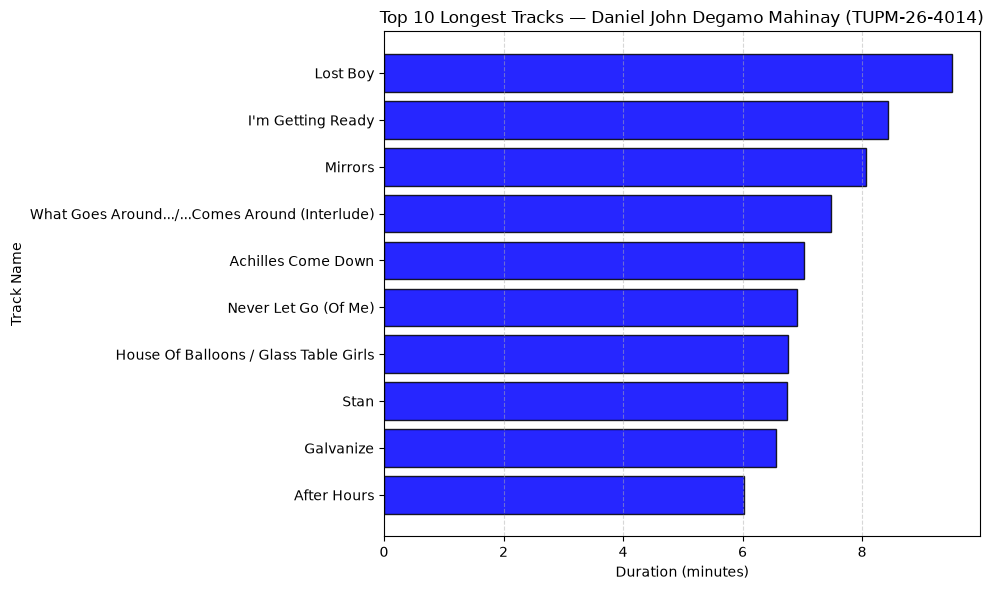

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Appendix Exercise 1

# ==========================================
# 1. INPUTS
# ==========================================
csv_path = "spotify_top_1000_tracks.csv"  # Spotify top 1000 tracks CSV
columns_used = ["track_name", "artist", "duration_min"]

# Student-specific parameters
student_name = "Daniel John Degamo Mahinay"
student_id = "TUPM-26-4014"
color_bar = "blue"

# Load dataset and select required columns
df = pd.read_csv(csv_path)[columns_used].dropna(subset=columns_used).copy()
df["duration_min"] = pd.to_numeric(df["duration_min"], errors="coerce")
df = df.dropna(subset=["duration_min"])

print("=== EXERCISE 1: INPUT SUMMARY ===")
print(f"Student Name : {student_name}")
print(f"Student ID   : {student_id}")
print(f"Bar Color    : {color_bar}")
print(f"Total Valid Rows: {len(df)}\n")

# ==========================================
# 2. CALCULATIONS
# ==========================================
# Step 2a: Sort dataset by duration_min in descending order
sorted_df = df.sort_values(by="duration_min", ascending=False)

# Step 2b: Select the top 10 longest tracks
top_10_df = sorted_df.head(10).reset_index(drop=True)

# ==========================================
# 3. OUTPUTS
# ==========================================
# Output 1: Table showing track name, artist, and duration
print("=== TOP 10 LONGEST TRACKS (TABLE) ===")
table_output = top_10_df.rename(
    columns={
        "track_name": "Track Name",
        "artist": "Artist",
        "duration_min": "Duration (min)",
    }
)
print(table_output.to_string(index=True))

# Output 2: Horizontal bar chart visualizing track duration
fig, ax = plt.subplots(figsize=(10, 6))

# Reverse order for plotting so the #1 longest track appears at the top
plot_df = top_10_df.iloc[::-1]

ax.barh(
    y=plot_df["track_name"],
    width=plot_df["duration_min"],
    color=color_bar,
    edgecolor="black",
    alpha=0.85,
)

ax.set_xlabel("Duration (minutes)")
ax.set_ylabel("Track Name")
ax.set_title(f"Top 10 Longest Tracks — {student_name} ({student_id})")
ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Columns in CSV: ['track_name', 'artist', 'album', 'release_date', 'popularity', 'spotify_url', 'id', 'duration_min']
                 track_name          artist  \
0  All The Stars (with SZA)  Kendrick Lamar   
1                   Starboy      The Weeknd   
2                  Señorita    Shawn Mendes   

                                               album release_date  popularity  \
0  Black Panther The Album Music From And Inspire...   2018-02-09          95   
1                                            Starboy   2016-11-25          90   
2                                           Señorita   2019-06-21          80   

                                         spotify_url                      id  \
0  https://open.spotify.com/track/3GCdLUSnKSMJhs4...  3GCdLUSnKSMJhs4Tj6CV3s   
1  https://open.spotify.com/track/7MXVkk9YMctZqd1...  7MXVkk9YMctZqd1Srtv4MB   
2  https://open.spotify.com/track/0TK2YIli7K1leLo...  0TK2YIli7K1leLovkQiNik   

   duration_min  
0      3.869767  
1      3.840

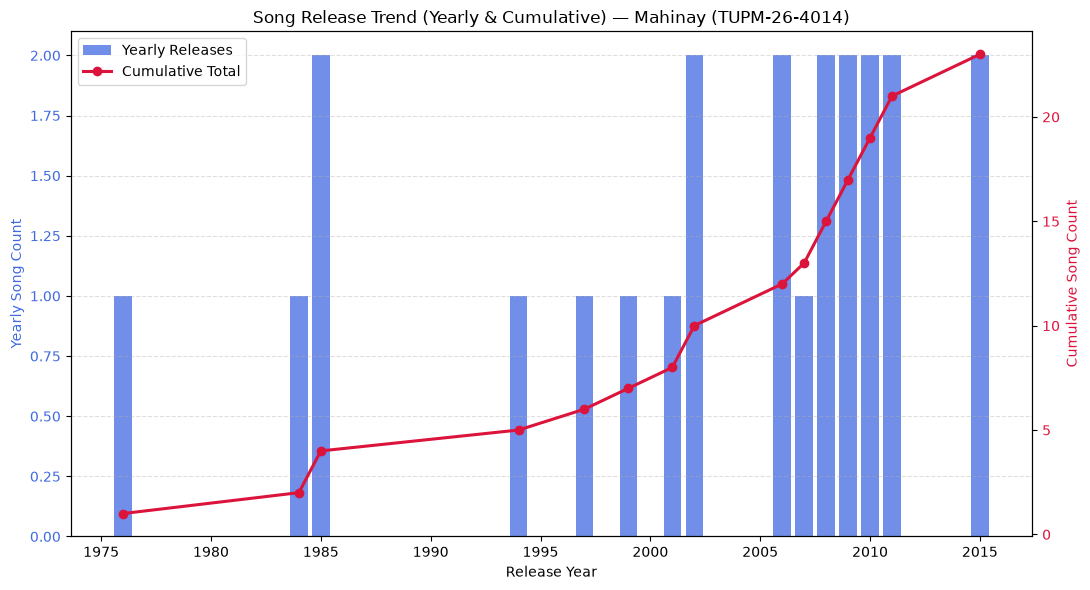

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

raw_df = pd.read_csv(csv_path)
print("Columns in CSV:", list(raw_df.columns))
print(raw_df.head(3))

# Appendix Exercise 2

import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. INPUTS
# ==========================================
csv_path = "spotify_top_1000_tracks.csv"  # Spotify top 1000 tracks CSV[cite: 1]

# Student-specific parameters
student_name = "Mahinay"
student_id = "TUPM-26-4014"  #[cite: 3]
color_bar = "royalblue"  #[cite: 1, 3]
color_line = "crimson"  #[cite: 1, 3]

raw_df = pd.read_csv(csv_path)

# Find the matching year column automatically
candidate_cols = [
    c for c in raw_df.columns if "year" in c.lower() or "release" in c.lower()
]
print("Detected year/release columns:", candidate_cols)

if "year" in raw_df.columns:
    year_series = raw_df["year"]
elif candidate_cols:
    year_col = candidate_cols[0]
    print(f"Using '{year_col}' as the year source column.")
    # Handle either numeric year or date string like 'YYYY-MM-DD'
    numeric_try = pd.to_numeric(raw_df[year_col], errors="coerce")
    if numeric_try.notna().sum() > 0:
        year_series = numeric_try
    else:
        year_series = pd.to_datetime(raw_df[year_col], errors="coerce").dt.year
else:
    raise KeyError(
        f"No year/release column found. Available columns: {list(raw_df.columns)}"
    )

df = pd.DataFrame({"year": year_series}).dropna(subset=["year"]).copy()
df["year"] = pd.to_numeric(df["year"], errors="coerce").dropna().astype(int)

print("=== EXERCISE 2: INPUT SUMMARY ===")
print(f"Student Name : {student_name}")
print(f"Student ID   : {student_id}")
print(f"Bar Color    : {color_bar}")
print(f"Line Color   : {color_line}")
print(f"Year Range   : {df['year'].min()} - {df['year'].max()}\n")

# ==========================================
# 2. CALCULATIONS
# ==========================================
yearly_counts = (
    df.groupby("year")
    .size()
    .reset_index(name="yearly_songs")
    .sort_values("year")
)
yearly_counts["cumulative_songs"] = yearly_counts["yearly_songs"].cumsum()

print("=== YEARLY & CUMULATIVE SONG COUNTS ===")
print(yearly_counts.to_string(index=False))

# ==========================================
# 3. OUTPUTS
# ==========================================
fig, ax1 = plt.subplots(figsize=(11, 6))

ax1.bar(
    yearly_counts["year"],
    yearly_counts["yearly_songs"],
    color=color_bar,
    alpha=0.75,
    label="Yearly Releases",
)
ax1.set_xlabel("Release Year")
ax1.set_ylabel("Yearly Song Count", color=color_bar)
ax1.tick_params(axis="y", labelcolor=color_bar)
ax1.grid(axis="y", linestyle="--", alpha=0.4)

ax2 = ax1.twinx()
ax2.plot(
    yearly_counts["year"],
    yearly_counts["cumulative_songs"],
    color=color_line,
    marker="o",
    linewidth=2.2,
    label="Cumulative Total",
)
ax2.set_ylabel("Cumulative Song Count", color=color_line)
ax2.tick_params(axis="y", labelcolor=color_line)

plt.title(f"Song Release Trend (Yearly & Cumulative) — {student_name} ({student_id})")

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper left")

plt.tight_layout()
plt.show()

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Appendix Exercise 3

# ==========================================
# 1. INPUTS
# ==========================================
csv_path = "spotify_top_1000_tracks.csv"  # Spotify top 1000 tracks CSV[cite: 2, 5]

# Student-specific parameters[cite: 2, 5]
student_name = "Daniel John Degamo Mahinay"  #[cite: 5]
student_id = "TUPM-26-4014"  #[cite: 5]
cmap_color = "viridis"  #[cite: 5]

raw_df = pd.read_csv(csv_path)
print("Available CSV columns:", list(raw_df.columns))

# Resolve 'year' column automatically (handles 'year', 'release_date', etc.)
if "year" in raw_df.columns:
    year_series = pd.to_numeric(raw_df["year"], errors="coerce")
else:
    year_candidates = [
        c for c in raw_df.columns
        if "year" in c.lower() or "release" in c.lower() or "date" in c.lower()
    ]
    if not year_candidates:
        raise KeyError(f"No 'year' or release/date column found in CSV: {list(raw_df.columns)}")
    yr_col = "release_date" if "release_date" in raw_df.columns else year_candidates[0]
    print(f"Using '{yr_col}' to derive 'year'.")
    extracted_yr = raw_df[yr_col].astype(str).str.extract(r"(\b\d{4}\b)")[0]
    year_series = pd.to_numeric(extracted_yr, errors="coerce")
    missing_mask = year_series.isna()
    if missing_mask.any():
        dt_years = pd.to_datetime(raw_df.loc[missing_mask, yr_col], errors="coerce").dt.year
        year_series.loc[missing_mask] = dt_years

# Resolve 'duration_min' column automatically (supports duration_min or duration_ms)
if "duration_min" in raw_df.columns:
    dur_series = pd.to_numeric(raw_df["duration_min"], errors="coerce")
elif "duration_ms" in raw_df.columns:
    print("Using 'duration_ms' converted to minutes as 'duration_min'.")
    dur_series = pd.to_numeric(raw_df["duration_ms"], errors="coerce") / 60000.0
else:
    dur_candidates = [c for c in raw_df.columns if "duration" in c.lower()]
    if not dur_candidates:
        raise KeyError(f"No duration column found in CSV: {list(raw_df.columns)}")
    dur_series = pd.to_numeric(raw_df[dur_candidates[0]], errors="coerce")

# Resolve 'popularity' column automatically
if "popularity" in raw_df.columns:
    pop_series = pd.to_numeric(raw_df["popularity"], errors="coerce")
else:
    pop_candidates = [c for c in raw_df.columns if "popular" in c.lower()]
    if not pop_candidates:
        raise KeyError(f"No popularity column found in CSV: {list(raw_df.columns)}")
    pop_series = pd.to_numeric(raw_df[pop_candidates[0]], errors="coerce")

df = pd.DataFrame({
    "duration_min": dur_series,
    "popularity": pop_series,
    "year": pd.to_numeric(year_series, errors="coerce"),
}).dropna().copy()
df["year"] = df["year"].astype(int)

print("=== EXERCISE 3: INPUT SUMMARY ===")
print(f"Student Name    : {student_name}")
print(f"Student ID      : {student_id}")
print(f"Colormap        : {cmap_color}")
print(f"Total Valid Rows: {len(df)}")
print(f"Years Available : {df['year'].min()} - {df['year'].max()}\n")

# ==========================================
# 2. CALCULATIONS
# ==========================================
# Subset/group data by year to show progression over time[cite: 2]
years = sorted(df["year"].unique())
yearly_subsets = {yr: df[df["year"] <= yr] for yr in years}

x_min, x_max = df["duration_min"].min(), df["duration_min"].max()
y_min, y_max = df["popularity"].min(), df["popularity"].max()

# ==========================================
# 3. OUTPUTS
# ==========================================
fig, ax = plt.subplots(figsize=(9, 6))

initial_data = yearly_subsets[years[0]]
hb = ax.hexbin(
    x=initial_data["duration_min"],
    y=initial_data["popularity"],
    gridsize=10,
    cmap=cmap_color,
    mincnt=1,
    extent=(x_min, x_max, y_min, y_max),
)
cbar = fig.colorbar(hb, ax=ax, label="Song Density (Count)")

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_xlabel("Duration (minutes)")
ax.set_ylabel("Popularity")
ax.set_title(
    f"Duration vs. Popularity Density (Year: {years[0]}) | "
    f"{student_name} ({student_id})"
)


def update(frame_year):
    global hb
    subset = yearly_subsets[frame_year]
    hb.remove()
    hb = ax.hexbin(
        x=subset["duration_min"],
        y=subset["popularity"],
        gridsize=10,
        cmap=cmap_color,
        mincnt=1,
        extent=(x_min, x_max, y_min, y_max),
    )
    hb.autoscale()
    cbar.update_normal(hb)
    ax.set_title(
        f"Duration vs. Popularity Density (Year: {frame_year}) | "
        f"{student_name} ({student_id})"
    )
    return (hb,)


anim = FuncAnimation(
    fig,
    func=update,
    frames=years,
    interval=500,
    blit=False,
    repeat=True,
)

anim.save("exercise3_hexbin_animation.gif", writer="pillow", fps=2)

# Optional: save animation as a GIF file in your project folder
# anim.save("exercise3_hexbin_animation.gif", writer="pillow", fps=2)

plt.tight_layout()
plt.close(fig)
display(HTML(anim.to_jshtml()))

Available CSV columns: ['track_name', 'artist', 'album', 'release_date', 'popularity', 'spotify_url', 'id', 'duration_min']
Using 'release_date' to derive 'year'.
=== EXERCISE 3: INPUT SUMMARY ===
Student Name    : Daniel John Degamo Mahinay
Student ID      : TUPM-26-4014
Colormap        : viridis
Total Valid Rows: 1000
Years Available : 1976 - 2025

